<a href="https://colab.research.google.com/github/dhrishithagcd24-collab/DLG_LAB/blob/main/1BM24CD018_Dhrishitha_G_Program6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6 — Bidirectional RNN for Music Generation
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** Treat a melody as a sequence of note *tokens*. A **two-layer Bidirectional LSTM**
reads the sequence and, at **every** time step, predicts the **next** note (a language-model
objective). After training we *generate* a new melody by predicting one note at a time and
sliding a window forward.

---
### How to use this notebook
Replace every `None  # TODO (Qn)` with the correct value or line of code. Run cells top to
bottom. Cells marked *(given — do not edit)* set things up for you.

> **Heads-up (you will analyse this):** the dataset here is *random* notes. Watch the accuracy
> and ask yourself in Task 7 whether it really means the model learned music.


## Step 0 — Imports *(given — do not edit)*

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Build the dataset (next-token pairs)

We have `num_sequences` melodies, each `sequence_length` notes long, drawn from a vocabulary of
`num_notes` distinct notes. Turn each melody into an **(input, target)** pair where the target is
the input **shifted left by one** (predict the next note), then **one-hot encode** both.

*Hints:* the input is every note **except the last**; the target is every note **except the
first**. One-hot vectors have length `num_notes`.


In [ ]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:, :-1]
y_train =data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = num_notes   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


#### Quick check *(given — run to verify Task 1)*

In [ ]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the Bidirectional LSTM model

Build a `Sequential` model with:
1. an **Input** of shape `(sequence_length-1, num_notes)` = `(29, 50)`;
2. **two Bidirectional LSTM layers**, 128 units each, **returning sequences** (an output at every
   step);
3. a **TimeDistributed Dense** output with `num_notes` units and **softmax** — one shared
   per-step note classifier.

*Hints:* a bidirectional layer is `layers.Bidirectional(layers.LSTM(units, return_sequences=...))`.
With 128 units per direction the layer outputs `2 * 128 = 256` features per step.


In [ ]:
model = models.Sequential()

model.add(layers.Input(
    shape=(sequence_length-1, num_notes)
))

# Q2a: First Bidirectional LSTM
model.add(layers.Bidirectional(
    layers.LSTM(128, return_sequences=True)
))

# Q2b: Second Bidirectional LSTM
model.add(layers.Bidirectional(
    layers.LSTM(128, return_sequences=True)
))

# Q2c: TimeDistributed Dense output
model.add(layers.TimeDistributed(
    layers.Dense(num_notes, activation='softmax')
))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** From the summary, the first Bi-LSTM shows **183,296** parameters. Verify
it by hand with `2 * 4 * [(features + units) * units + units]`, where `features = 50`,
`units = 128`. Then explain why the **second** Bi-LSTM has *more* parameters than the first.

> **Your answer (Q2d):** params = 2 × 4 × [ (____ + ____) × ____ + ____ ] = ________ ;
> the second layer is larger because ____.


## Task 3 — Compile and train

Compile with the **Adam** optimiser (learning rate `0.001`), **categorical crossentropy** loss
(targets are one-hot), and track **accuracy**. Train for 20 epochs, batch size 64, holding out
20% for validation.


In [ ]:
# Q3a: Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Q3b: Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 356ms/step - accuracy: 0.1046 - loss: 3.8849 - val_accuracy: 0.1860 - val_loss: 3.8449
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 378ms/step - accuracy: 0.1596 - loss: 3.7750 - val_accuracy: 0.0947 - val_loss: 3.6572
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.1190 - loss: 3.5165 - val_accuracy: 0.1360 - val_loss: 3.3920
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 418ms/step - accuracy: 0.1613 - loss: 3.2138 - val_accuracy: 0.1850 - val_loss: 3.0727
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 388ms/step - accuracy: 0.2145 - loss: 2.8529 - val_accuracy: 0.2500 - val_loss: 2.6932
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 294ms/step - accuracy: 0.2828 - loss: 2.4408 - val_accuracy: 0.3231 - val_loss: 2.2884
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 442ms/step - accuracy: 0.3627 - loss: 2.0339 - val_accuracy: 0.4043 - val_loss: 1.9000
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.4517 - loss: 1.6756 - val_accuracy: 

## Task 4 — Plot the training history *(fill the blanks)*

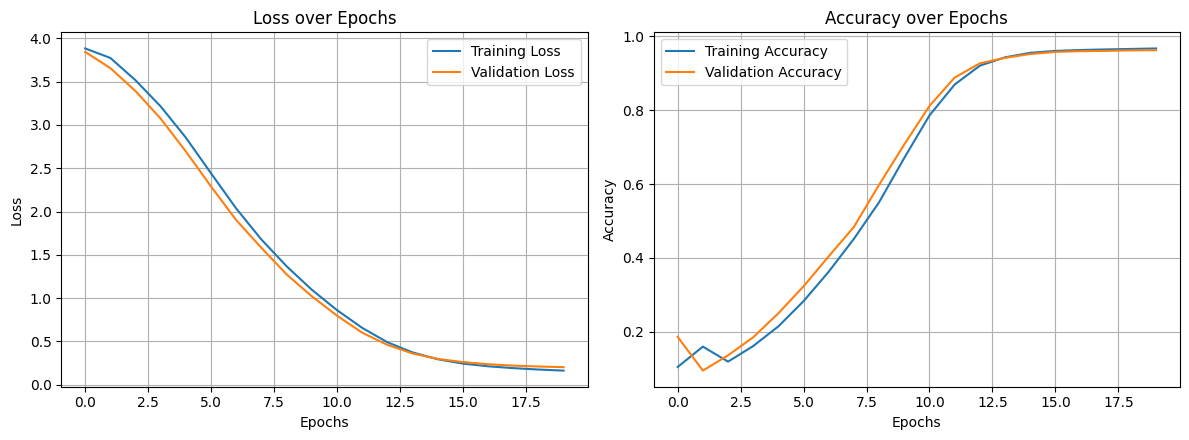

In [ ]:
plt.figure(figsize=(12, 4.5))

# Training and validation loss
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

# Training and validation accuracy
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Task 5 — Generate a new sequence (greedy decoding)

Complete the generation loop: predict with the model, read the distribution at the **last** time
step, take the most likely note (`argmax`), append it, then **slide the window** by dropping the
first step and appending the new note (one-hot).


In [ ]:
def generate_music(model, start_sequence, num_generated_notes=50):

    generated = []
    current_sequence = start_sequence

    for _ in range(num_generated_notes):

        pred = model.predict(current_sequence, verbose=0)

        # Q5a: Predict the most likely next note
        next_note = np.argmax(pred[:, -1, :], axis=-1)

        generated.append(int(next_note[0]))

        # Convert predicted note into one-hot encoding
        oh = to_categorical(
            next_note,
            num_classes=num_notes
        ).reshape(1, 1, num_notes)

        # Q5b: Slide the sequence window
        current_sequence = np.concatenate(
            [current_sequence[:, 1:, :], oh],
            axis=1
        )

    return generated


# Starting sequence
start = np.random.randint(
    0, num_notes,
    size=(1, sequence_length-1)
)

start = to_categorical(start, num_classes=num_notes)

# Generate 50 notes
generated_music = generate_music(
    model,
    start,
    num_generated_notes=50
)

print("Generated:", generated_music)

Generated: [46, 46, 46, 46, 46, 46, 46, 46, 46, 46, 46, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11]


## Task 6 — Piano-roll of the generated melody *(fill one blank)*

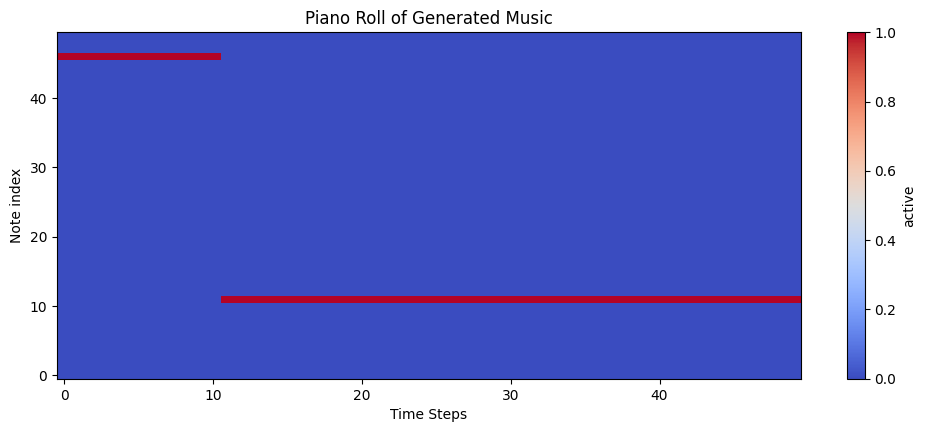

In [ ]:
piano_roll = np.zeros((num_notes, len(generated_music)))

for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 4.5))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower',
    interpolation='nearest'
)

plt.colorbar(label='active')

plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps')
plt.ylabel('Note index')

plt.show()

## Task 7 — Analysis *(write your answers here)*

1. The two Bi-LSTM layers both use `return_sequences=True`. What would break if you set it to
   `False` on the first layer?
2. Why is the first Bi-LSTM's output width **256** when the LSTM has 128 units?
3. What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?
4. You trained on **random** notes, yet accuracy reaches ~96%. **Explain the mechanism.**
   *(Hint: the target at step t equals the input at step t+1 — which direction of a bidirectional
   layer can already see it?)*
5. Why is a **bidirectional** model a poor choice for *autoregressive generation*, and what two
   changes would make this an honest music generator?

> **Your answers:**
> 1. The first LSTM would return only the final output instead of outputs at every time step. The second LSTM needs a sequence as input, so the model would not work as intended.

> 2. Because a Bidirectional LSTM combines forward and backward outputs.
128 + 128 = 256 features.

> 3.It applies the same Dense layer independently at every time step and predicts probabilities for all 50 notes.

> 4. This happens because of label leakage. The target at time step t is the input at time step t+1. The backward LSTM can see the next input and indirectly access the target, resulting in artificially high accuracy.
> 5. A bidirectional model uses both past and future information. During music generation, future notes are not available.

Two changes to make it an honest music generator:

Replace Bidirectional LSTM layers with normal unidirectional LSTM layers.

Train the model on actual music sequences using next-note prediction.

## (Optional) Stretch — make it causal
Copy the model into a new cell, remove **both** `Bidirectional` wrappers (plain `LSTM`), retrain,
and compare the accuracy curve. Explain why the (lower) number is the more honest one.
